# ML & Threat Scoring — Kaavya's module

**Goal of this notebook:** take real UCES events, turn them into per-window features, score them with an
unsupervised Isolation Forest, evaluate it honestly, and produce the threat score the dashboard will show.

```
uces-events  ->  windowed features  ->  Isolation Forest (+ range guard)  ->  anomaly_100
                                                                              \
                       Ananya: rule_100, corr_100  ---------------------------->  fuse()  ->  threat_score, alert_level
                       honeypot interactions  --------------------------------->  /
```

**Read this before quoting any number from this notebook**

1. The sample dump is **baseline traffic only**. It contains no attacks, so detection quality cannot be measured on it.
2. The attacks used for evaluation are **simulated by `attack_sim.py`** and injected into the held-out day. Treat the
   results as proof that the pipeline works and as a map of where it is weak, not as final accuracy figures.
3. The rule engine used in the comparison is a **stand-in** for Ananya's. Correlation does not exist yet and is zero.

Everything reusable lives in `uces_ml.py` (module) so Arnav / Ananya can import the same code.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import uces_ml as U
import attack_sim as A

SAMPLE = "uces-sample.jsonl"            # UCES dump from Arnav - keep it next to this notebook
OUT = Path("outputs")
for sub in ("figures", "models", "results"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

D = lambda s: pd.Timestamp(s, tz="UTC")
CALIB_START, TEST_START = D("2026-10-29"), D("2026-10-30")   # train < Oct 29 | calibrate = Oct 29 | test >= Oct 30
ALERT_T = 50      # alert threshold on the 0-100 anomaly score (= 99th percentile of held-out normal windows)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Load the real UCES sample

`load_uces()` follows the schema rules: 24 flat fields, **null fields are absent from the JSON**, so every missing
key is treated as null (never assume a fixed column set per row).

In [2]:
ev = U.load_uces(SAMPLE)
print(f"{len(ev):,} events | malformed lines skipped: {ev.attrs['bad_lines']} | "
      f"{ev.event_time.min():%Y-%m-%d %H:%M} -> {ev.event_time.max():%Y-%m-%d %H:%M} UTC")
display(ev.groupby(["source", "event_type"]).size().rename("events").to_frame())
display(ev.groupby("source")["host"].unique().rename("hosts").to_frame())
print("Null-key check: endpoint rows have no network fields ->",
      ev.loc[ev.source == "endpoint", ["src_ip", "dst_port", "bytes_out"]].isna().all().to_dict())

16,288 events | malformed lines skipped: 0 | 2026-10-27 18:30 -> 2026-10-31 09:40 UTC


events
source   event_type             
endpoint process_end        4104
         process_start      4104
honeypot client_version      365
         login               694
         session_closed      420
         session_connect     420
network  anomaly              26
         dns                1534
         flow               3146
         http                124
         quic                517
         tls                 834

,hosts
source,
endpoint,"[WS-ACCT-07, DESKTOP-H4T6WQ1, LAPTOP-R8N3V2XC,..."
honeypot,[cowrie-vm01]
network,[IDS-SENSOR-01]


Null-key check: endpoint rows have no network fields -> {'src_ip': True, 'dst_port': True, 'bytes_out': True}


## 2. Feature engineering

An Isolation Forest needs a **dense numeric vector**, but raw UCES rows are mostly null and mixed across sources. So events
are aggregated into **one row per entity per 60-second window** (the same `groupBy(window, key).agg(...)` Spark will run):

| Model | Entity | Features (per window) |
|---|---|---|
| Network | `src_ip` | event counts by type (flow, dns, tls, http, quic, anomaly), distinct dst IPs / ports / domains / **internal** dst IPs, events to **uncommon ports**, bytes & packets in/out (flow events only), out/in ratio |
| Endpoint | `host` | process starts/ends, distinct processes / parents / users, failed outcomes, shell launches, **Office-spawned shells**, encoded commands, max command-line length & entropy |

Counts and byte volumes are `log1p`-scaled: a few huge values would otherwise dominate the random splits.

In [3]:
common_ports = U.learn_common_ports(ev)          # ports carrying >= 1% of baseline events; everything else is 'uncommon'
net = U.build_network_features(ev, common_ports)
ep  = U.build_endpoint_features(ev)
print("common ports learned from baseline:", common_ports)
print(f"network windows: {len(net):,}  (median {net.n_events.median():.0f} events per window)")
print(f"endpoint windows: {len(ep):,}  (median {ep.n_start.median():.0f} process starts per window)")
display(net.sample(5, random_state=1).drop(columns="entity_type"))

common ports learned from baseline: [53, 80, 443, 445]
network windows: 3,553  (median 2 events per window)
endpoint windows: 5,284  (median 1 process starts per window)


,entity,window_start,n_events,n_flow,n_dns,n_tls,n_http,n_quic,n_anomaly,distinct_dst_ip,distinct_dst_port,distinct_domains,distinct_internal_dst,uncommon_port_events,bytes_out,bytes_in,packets_out,packets_in
93,192.168.10.21,2026-10-28 06:14:00+00:00,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,78.0,114.0,4.0,1.0
397,192.168.10.21,2026-10-29 09:21:00+00:00,2.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1730,192.168.10.23,2026-10-28 06:07:00+00:00,4.0,0.0,2.0,2.0,0.0,0.0,0.0,3.0,2.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0
1151,192.168.10.22,2026-10-29 04:52:00+00:00,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,13591.0,1534290.0,22.0,1281.0
321,192.168.10.21,2026-10-29 05:02:00+00:00,2.0,2.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,0.0,1.0,1.0,174.0,312.0,3.0,5.0


## 3. Split by time (never randomly)

| Slice | Dates | Used for |
|---|---|---|
| **train** | before Oct 29 | fit the Isolation Forest (no labels) |
| **calibrate** | Oct 29 | turn raw scores into the 0-100 scale; this slice is normal and *held out*, so the false-alarm rate it implies is honest |
| **test** | Oct 30 (+ injected attacks) | evaluation |

A random split would leak: windows one minute apart are near-duplicates.

In [4]:
def split(f):
    t = f.window_start
    return f[t < CALIB_START], f[(t >= CALIB_START) & (t < TEST_START)], f[t >= TEST_START]

ntr, nva, nte = split(net)
etr, eva, ete = split(ep)
display(pd.DataFrame({"train": [len(ntr), len(etr)], "calibrate": [len(nva), len(eva)], "test (normal)": [len(nte), len(ete)]},
                     index=["network windows", "endpoint windows"]))

,train,calibrate,test (normal)
network windows,1269,1155,1129
endpoint windows,1959,1763,1562


## 4. Fit the models

* **Isolation Forest** learns what normal windows look like. No labels are passed to `fit()`.
* **Range guard** (added after testing, see below) measures how far a feature exceeds the largest baseline value.
  `anomaly_100 = max(IF score, guard score)`.
* Both are calibrated on the held-out day: **50 = as extreme as the 99th percentile of normal windows (~1% false alarms),
  80 = more extreme than any normal window seen, 100 = one further baseline-spread beyond that.**

**Why the guard exists (a real finding):** Isolation Forest cannot extrapolate. A window far *outside* the training range lands in
the same extreme leaf as one just outside it, so a 200-port scan scored barely above normal traffic. Section 6 shows this as an
ablation (IF only vs IF + guard).

features that never vary in the baseline (Isolation Forest is blind to them -> rules must cover them):
  network : none
  endpoint: ['n_failed', 'n_office_shell', 'n_enc_cmd']


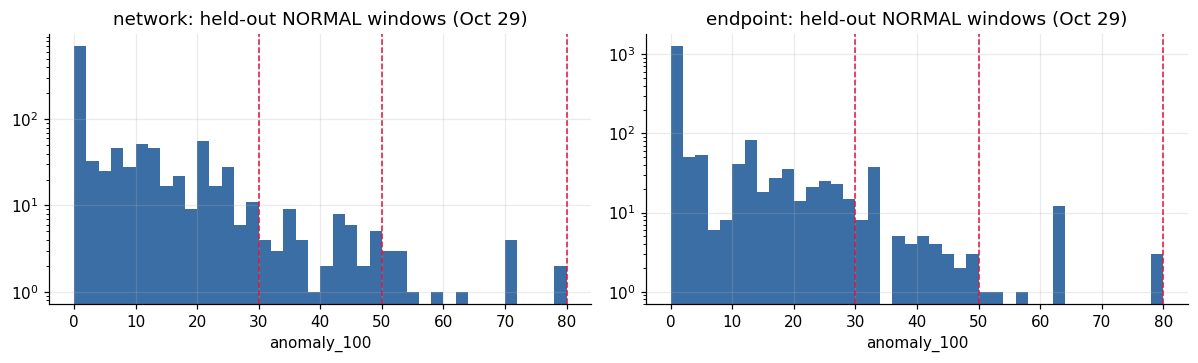

share of held-out normal windows at/above 50: {'network': np.float64(0.013), 'endpoint': np.float64(0.0102)}


In [5]:
net_model = U.AnomalyModel("network").fit(ntr, nva)
ep_model  = U.AnomalyModel("endpoint").fit(etr, eva)
print("features that never vary in the baseline (Isolation Forest is blind to them -> rules must cover them):")
print("  network :", net_model.constant_features_ or "none")
print("  endpoint:", ep_model.constant_features_ or "none")

cal_net, cal_ep = net_model.score(nva), ep_model.score(eva)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for ax, d, name in [(axes[0], cal_net, "network"), (axes[1], cal_ep, "endpoint")]:
    ax.hist(d.anomaly_100, bins=40, color="#3b6ea5")
    for x in (30, 50, 80):
        ax.axvline(x, color="crimson", ls="--", lw=1)
    ax.set_title(f"{name}: held-out NORMAL windows (Oct 29)"); ax.set_xlabel("anomaly_100"); ax.set_yscale("log")
plt.tight_layout(); plt.savefig(OUT / "figures" / "fig1_calibration.png"); plt.show()
print("share of held-out normal windows at/above 50:",
      {"network": round((cal_net.anomaly_100 >= 50).mean(), 4), "endpoint": round((cal_ep.anomaly_100 >= 50).mean(), 4)})

## 5. Ground truth: simulated attacks injected into the test day

Eleven scenarios (8 network, 3 endpoint), deliberately a mix of loud and quiet:

| Loud | Quiet / hard |
|---|---|
| 200-port scan, SMB fan-out, 25 MB exfiltration, recon burst | 12-port "stealth" scan, 1.5 MB exfil, 8-minute beacon on port 4444, one `certutil` download |

The log has the same shape you will produce from real runs (Nmap / Hydra): `attack_id, attack_type, entity, start, end`.

In [6]:
records, attack_log = A.build_scenarios("2026-10-30")
sim = U.events_from_records(records)
test_events = pd.concat([ev[ev.event_time >= TEST_START], sim], ignore_index=True)

display(attack_log.assign(start=attack_log.start.dt.strftime("%H:%M:%S"), end=attack_log.end.dt.strftime("%H:%M:%S")))

ns = U.label_windows(net_model.score(U.build_network_features(test_events, common_ports)), attack_log)
es = U.label_windows(ep_model.score(U.build_endpoint_features(test_events)), attack_log)
test = pd.concat([ns, es], ignore_index=True)
print(f"test windows: {len(test):,}   attack windows: {int(test.label.sum())}   normal windows: {int((test.label == 0).sum())}")

,attack_id,attack_type,entity,entity_type,start,end
0,N1,port_scan_heavy,192.168.10.23,ip,10:12:00,10:12:45
1,N2,port_scan_stealth,192.168.10.21,ip,11:20:00,11:20:55
2,N3,external_scan,203.0.113.50,ip,12:05:00,12:05:40
3,N4,exfil_large,192.168.10.24,ip,13:10:00,13:11:15
4,N5,exfil_moderate,192.168.10.22,ip,14:02:00,14:03:15
5,N6,dns_tunnel,192.168.10.21,ip,09:40:00,09:40:58
6,N7,smb_fanout,192.168.10.23,ip,15:30:00,15:30:50
7,N8,c2_beacon,192.168.10.22,ip,16:00:00,16:08:00
8,E1,office_encoded_ps,DESKTOP-7Q2K9LM,host,10:45:00,10:45:15
9,E2,recon_burst,LAPTOP-R8N3V2XC,host,11:50:00,11:50:55


test windows: 2,705   attack windows: 18   normal windows: 2687


## 6. Evaluation (ML only)

Accuracy is meaningless here (attack windows are ~1% of rows). We report **Precision, Recall, F1, FPR**, plus two
threshold-free numbers: **ROC-AUC** and **average precision**.

In [7]:
def eval_row(name, y, score, t=ALERT_T):
    m = U.classification_metrics(y, score >= t)
    m.update(U.threshold_free(y, score)); m["variant"] = name
    return m

ablation = pd.DataFrame([eval_row("Isolation Forest only", test.label, test.if_100),
                         eval_row("Isolation Forest + range guard", test.label, test.anomaly_100)])
ablation = ablation[["variant", "roc_auc", "avg_precision", "precision", "recall", "f1", "fpr", "tp", "fp", "fn", "tn"]]
display(ablation.round(3))
ablation.to_csv(OUT / "results" / "ablation_if_vs_guard.csv", index=False)

,variant,roc_auc,avg_precision,precision,recall,f1,fpr,tp,fp,fn,tn
0,Isolation Forest only,0.969,0.170,0.240,0.333,0.279,0.007,6,19,12,2668
1,Isolation Forest + range guard,0.990,0.947,0.425,0.944,0.586,0.009,17,23,1,2664


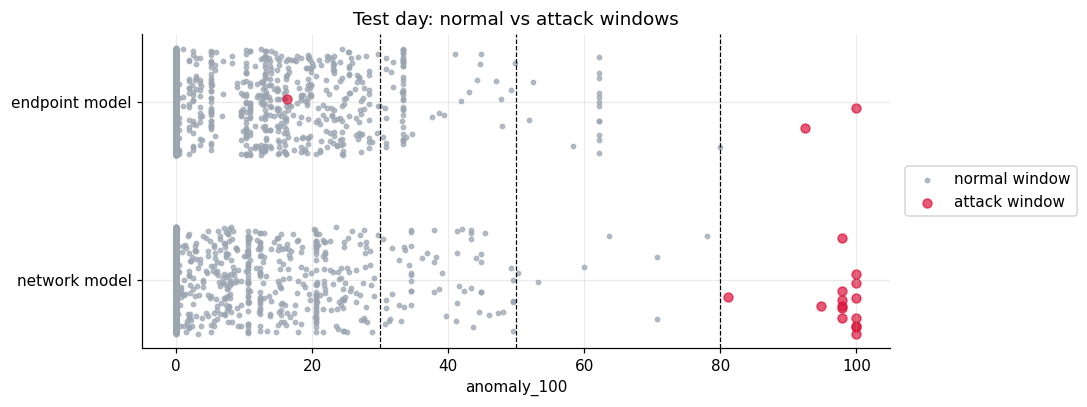

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
rng = np.random.default_rng(0)
for lab, col, nm, sz in [(0, "#9aa5b1", "normal window", 8), (1, "crimson", "attack window", 34)]:
    d = test[test.label == lab]
    ax.scatter(d.anomaly_100, rng.uniform(-.3, .3, len(d)) + (d.model == "endpoint"), s=sz, c=col, alpha=.7, label=nm)
for x in (30, 50, 80):
    ax.axvline(x, color="k", ls="--", lw=.8)
ax.set_yticks([0, 1], ["network model", "endpoint model"]); ax.set_xlabel("anomaly_100"); ax.legend(loc="center left", bbox_to_anchor=(1.01, .5))
ax.set_title("Test day: normal vs attack windows"); plt.tight_layout()
plt.savefig(OUT / "figures" / "fig2_test_scores.png"); plt.show()

,threshold,precision,recall,f1,fpr,tp,fp,fn,tn
0,20,0.044,0.944,0.084,0.138,17,372,1,2315
1,30,0.106,0.944,0.190,0.054,17,144,1,2543
2,40,0.218,0.944,0.354,0.023,17,61,1,2626
3,50,0.425,0.944,0.586,0.009,17,23,1,2664
4,60,0.500,0.944,0.654,0.006,17,17,1,2670
5,70,0.810,0.944,0.872,0.001,17,4,1,2683
6,80,0.944,0.944,0.944,0.000,17,1,1,2686
7,90,1.000,0.889,0.941,0.000,16,0,2,2687
8,100,1.000,0.444,0.615,0.000,8,0,10,2687


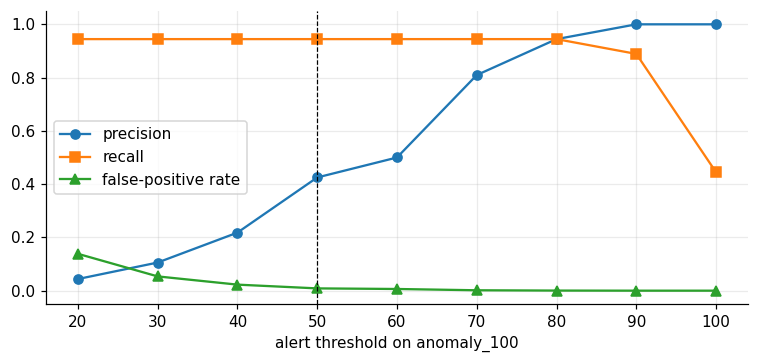

In [9]:
sw = U.sweep(test.label, test.anomaly_100, [20, 30, 40, 50, 60, 70, 80, 90, 100])
display(sw.round(3))
sw.to_csv(OUT / "results" / "threshold_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(sw.threshold, sw.precision, "-o", label="precision"); ax.plot(sw.threshold, sw.recall, "-s", label="recall")
ax.plot(sw.threshold, sw.fpr, "-^", label="false-positive rate")
ax.axvline(ALERT_T, color="k", ls="--", lw=.8); ax.set_xlabel("alert threshold on anomaly_100"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "fig3_threshold_sweep.png"); plt.show()

**How to read this:** the threshold was fixed at 50 *before* looking at attack scores (it comes from the held-out normal day), so
recall is not tuned on the test set. The false-alarm count is the number to watch: with ~1% FPR over a thousand windows a day you
will see a handful of false alerts, which is exactly why the project fuses several signals instead of alerting on one.

**Two-tier policy worth adopting:** score >= 50 goes to a review queue (about 1% of normal windows), score >= 80 raises an alert
("more extreme than every normal window in the baseline"). Both numbers come from the calibration day, not from the test day. The sweep
shows the 80 tier is far cleaner, but note that preferring it *after* seeing this table is mild tuning on the test set; confirm it on a
second held-out normal slice (real captures) before quoting it in the report.

## 7. Honeypot risk and threat fusion

```
Threat Score = 0.30 x Rule + 0.25 x Anomaly + 0.35 x Correlation + 0.10 x Honeypot
```

`fuse()` takes everything keyed on `(entity, window_start)`, all on 0-100. Ananya's engine only has to return two columns each:
`rule_100` and `corr_100`. Missing signals count as 0.

**Check this with the team:** with the formula exactly as written, no single signal can raise an alert on its own.

In [10]:
levels = pd.DataFrame({"evidence": ["Anomaly only (100)", "Rule only (100)", "Honeypot only (100)", "Rule + Anomaly",
                                    "Rule + Anomaly + Honeypot", "All four signals"],
                       "anomaly_100": [100, 0, 0, 100, 100, 100], "rule_100": [0, 100, 0, 100, 100, 100],
                       "honeypot_100": [0, 0, 100, 0, 100, 100], "corr_100": [0, 0, 0, 0, 0, 100]})
levels["window_start"] = pd.Timestamp("2026-10-30", tz="UTC")
rows = []
for _, r in levels.iterrows():
    one = pd.DataFrame([{"entity": "x", "entity_type": "ip", "window_start": r.window_start, "anomaly_100": r.anomaly_100}])
    f = U.fuse(one, rule=pd.DataFrame([{"entity": "x", "window_start": r.window_start, "rule_100": r.rule_100}]),
               corr=pd.DataFrame([{"entity": "x", "window_start": r.window_start, "corr_100": r.corr_100}]),
               honeypot=pd.DataFrame([{"entity": "x", "window_start": r.window_start, "honeypot_100": r.honeypot_100}]))
    rows.append({"evidence": r.evidence, "threat_score": f.threat_score[0], "alert_level": f.alert_level[0]})
display(pd.DataFrame(rows))

,evidence,threat_score,alert_level
0,Anomaly only (100),25.0,Normal
1,Rule only (100),30.0,Normal
2,Honeypot only (100),10.0,Normal
3,Rule + Anomaly,55.0,Medium
4,Rule + Anomaly + Honeypot,65.0,Medium
5,All four signals,100.0,Critical


So a perfect anomaly score alone caps at 25 (*Normal*), a perfect rule hit at 30 (*Normal*), and a honeypot touch at 10. Only
agreement between signals (and especially correlation) reaches High / Critical. That is the "evidence-based alerting" idea, but it
also means a loud single-source attack is under-rated. Options for the team to decide: keep the formula as specified and report the
trade-off, or add an override such as "any signal at 100 is at least Medium".

Honeypot signal on the real sample:

In [11]:
hp = U.honeypot_risk(ev)
print(f"{ev[ev.source == 'honeypot'].src_ip.nunique()} distinct attacker IPs touched the honeypot; {len(hp)} (ip, window) rows flagged "
      f"(incl. {5} look-back windows)")
overlap = set(hp.entity) & set(net.entity)
print("attacker IPs that ALSO appear as a network-sensor source in this sample:", len(overlap))

70 distinct attacker IPs touched the honeypot; 2587 (ip, window) rows flagged (incl. 5 look-back windows)
attacker IPs that ALSO appear as a network-sensor source in this sample: 0


In this sample the honeypot attackers and the monitored network never overlap, so the honeypot term can only matter once an attacker
that touched Cowrie also shows up in the network/endpoint data (the real cross-source case). The code supports it; the sample cannot exercise it.

## 8. Rules vs ML vs Hybrid (Phase 8 comparison harness)

Thresholds are chosen **on the calibration day only**, never on the test day:

* **Rules (stand-in):** fixed a-priori thresholds, alert if `rule_100 >= 50`.
* **ML only:** `anomaly_100 >= 50`.
* **Hybrid:** doc formula with correlation not yet available, so weights are renormalised over the signals present;
  alert threshold = 99th percentile of the hybrid score on the calibration day (same ~1% target false-alarm rate).

The stand-in rules cover port scans, internal fan-out, bulk upload, Office-spawned shells and encoded commands. They deliberately do
**not** cover DNS tunnelling, beaconing or LOLBin downloads. **That choice is mine, so the hybrid advantage below is built in by design.
Replace the stand-in with Ananya's real rules before using this table in the report.**

In [12]:
# calibration-day (normal) windows
cal = pd.concat([cal_net, cal_ep], ignore_index=True)
rules_cal = U.reference_rules(nva, eva)
fused_cal = U.fuse(cal, rule=rules_cal, honeypot=U.honeypot_risk(ev), renormalize=True)
fused_cal = fused_cal.merge(cal[["entity", "window_start"]], on=["entity", "window_start"])        # keep sensor/endpoint windows only
T_HYBRID = float(np.quantile(fused_cal.threat_score, 0.99))

# test day
rules_test = U.reference_rules(U.build_network_features(test_events, common_ports), U.build_endpoint_features(test_events))
fused_test = U.fuse(test, rule=rules_test, honeypot=U.honeypot_risk(test_events), renormalize=True)
cmp = fused_test.merge(test[["entity", "window_start", "label", "attack_id", "attack_type", "if_100", "guard_100", "driver"]],
                       on=["entity", "window_start"], how="inner")

methods = {"Rules only (stand-in)": (cmp.rule_100, 50), "ML only (IF + guard)": (cmp.anomaly_100, ALERT_T),
           "Hybrid (rule + ML + honeypot)": (cmp.threat_score, T_HYBRID)}
rows = []
for name, (s, t) in methods.items():
    m = U.classification_metrics(cmp.label, s >= t); m.update(U.threshold_free(cmp.label, s))
    m["approach"], m["threshold"] = name, round(t, 1); rows.append(m)
comparison = pd.DataFrame(rows)[["approach", "threshold", "precision", "recall", "f1", "fpr", "roc_auc", "tp", "fp", "fn", "tn"]]
display(comparison.round(3))
comparison.to_csv(OUT / "results" / "comparison_rules_ml_hybrid.csv", index=False)
print(f"hybrid threshold from calibration day: {T_HYBRID:.1f}")

,approach,threshold,precision,recall,f1,fpr,roc_auc,tp,fp,fn,tn
0,Rules only (stand-in),50.0,1.000,0.278,0.435,0.000,0.639,5,0,13,2687
1,ML only (IF + guard),50.0,0.425,0.944,0.586,0.009,0.990,17,23,1,2664
2,Hybrid (rule + ML + honeypot),19.8,0.436,0.944,0.596,0.008,0.990,17,22,1,2665


hybrid threshold from calibration day: 19.8

In [13]:
atk = cmp[cmp.label == 1].copy()
atk["Rules"] = atk.rule_100 >= 50
atk["IF only"] = atk.if_100 >= ALERT_T
atk["IF+guard"] = atk.anomaly_100 >= ALERT_T
atk["Hybrid"] = atk.threat_score >= T_HYBRID
per_attack = (atk.groupby(["attack_id", "attack_type"])
                 .agg(windows=("label", "size"), Rules=("Rules", "max"), IF_only=("IF only", "max"), IF_plus_guard=("IF+guard", "max"),
                      Hybrid=("Hybrid", "max"), max_anomaly=("anomaly_100", "max"),
                      driver=("driver", lambda s: next((x for x in s if x), "")))
                 .reset_index())
for c in ("Rules", "IF_only", "IF_plus_guard", "Hybrid"):
    per_attack[c] = per_attack[c].map({True: "caught", False: "MISSED"})
display(per_attack)
per_attack.to_csv(OUT / "results" / "per_attack_detection.csv", index=False)

,attack_id,attack_type,windows,Rules,IF_only,IF_plus_guard,Hybrid,max_anomaly,driver
0,E1,office_encoded_ps,1,caught,caught,caught,caught,92.44,cmd_entropy_max
1,E2,recon_burst,1,MISSED,MISSED,caught,caught,100.00,n_start
2,E3,lolbin_download,1,MISSED,MISSED,MISSED,MISSED,16.24,
3,N1,port_scan_heavy,1,caught,caught,caught,caught,100.00,uncommon_port_events
4,N2,port_scan_stealth,1,MISSED,MISSED,caught,caught,100.00,uncommon_port_events
5,N3,external_scan,1,caught,caught,caught,caught,100.00,uncommon_port_events
6,N4,exfil_large,1,caught,MISSED,caught,caught,100.00,packets_out
7,N5,exfil_moderate,1,MISSED,MISSED,caught,caught,81.06,packets_out
8,N6,dns_tunnel,1,MISSED,MISSED,caught,caught,100.00,n_dns
9,N7,smb_fanout,1,caught,caught,caught,caught,100.00,distinct_internal_dst


**What to take from the table**

* Check whether the hybrid row actually beats the ML-only row. If it does not, that is a finding, not a bug: once the range guard is in place
  the ML score already flags the same extreme windows the stand-in rules were written for, so the rules add determinism and
  explainability (and cover features that never vary in the baseline) rather than extra recall on loud attacks.

* Rules catch what they were written for and nothing else; ML catches things no rule was written for.
* `driver` is the feature that pushed the window over the baseline. That is the **evidence string** for the dashboard
  ("n_dns far above baseline"), which makes an ML alert explainable.
* Anything marked **MISSED** by every method is a real gap, not noise. A single `certutil` download looks like a normal process start
  (nothing is statistically unusual); it needs an IOC / URL rule (Ananya's threat-intel matching), not anomaly detection.

## 9. Deliverables for the pipeline

* `models/ml_bundle.joblib` - both fitted models + learned common ports (used by `score_stream.py`)
* `results/*.csv` and `figures/*.png` - tables and plots for the report
* `results/alerts_sample.jsonl` - proposed alert documents for Elasticsearch (entity, window, scores, level, evidence), strongest first. Agree the field names with Arnav.
  `alert_level` uses the document's bands, which only line up once correlation scores exist; until then rank by `threat_score` / `anomaly_100`.

In [14]:
U.save_bundle(OUT / "models" / "ml_bundle.joblib", net_model, ep_model, common_ports)

alerts = fused_test.merge(test[["entity", "window_start", "driver", "bucket"]], on=["entity", "window_start"], how="left")
alerts = alerts[alerts.threat_score >= T_HYBRID].sort_values("threat_score", ascending=False).copy()
alerts["window_start"] = alerts.window_start.dt.strftime("%Y-%m-%dT%H:%M:%SZ")
alerts[["entity", "entity_type", "window_start", "anomaly_100", "rule_100", "corr_100", "honeypot_100",
        "threat_score", "alert_level", "bucket", "driver"]].to_json(OUT / "results" / "alerts_sample.jsonl", orient="records", lines=True)
print(f"{len(alerts)} alert documents written; first one:")
print(alerts.iloc[0][["entity", "window_start", "anomaly_100", "rule_100", "threat_score", "alert_level", "driver"]].to_dict())

39 alert documents written; first one:
{'entity': '192.168.10.23', 'window_start': '2026-10-30T10:12:00Z', 'anomaly_100': 100.0, 'rule_100': 90.0, 'threat_score': 80.0, 'alert_level': 'High', 'driver': 'uncommon_port_events'}


## 10. Moving from sample to real data - checklist

1. **Capture a clean baseline** on the real laptop (45+ min normal use) and a second held-out normal slice. Real traffic has more uncommon ports,
   so the baseline `uncommon_port_events` will vary and the model will be less trigger-happy than here.
2. **Run real attacks** (Nmap from another device, Hydra against Cowrie) and log `start/end/entity` in the same `attack_log` shape; swap
   `A.build_scenarios()` for that file. Report counts with every metric: real attack windows will number in the tens, not thousands.
3. **Replace `reference_rules()`** with Ananya's `rule_100` and `corr_100` (columns `entity, window_start, rule_100` / `corr_100`) and re-run section 8.
4. **Watch the self-generated traffic**: Tailscale and Filebeat-to-Kafka shipping appear in the laptop's own capture. Keep them in the baseline.
5. **Retrain** whenever the baseline changes materially (new hosts, new software); the whole notebook re-runs in seconds.